In [4]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, recall_score
import lightgbm as lgb
import matplotlib.pyplot as plt

In [ ]:
df_train = pd.read_excel("两年训练集过采样.xlsx")
print(df_train.head())

In [6]:
df_test = pd.read_excel("73平衡测试集.xlsx")

In [7]:
# 特征和标签定义
X_train = df_train.drop(columns=['com_endow'])
y_train = df_train['com_endow']
X_test = df_test.drop(columns=['com_endow'])
y_test = df_test['com_endow']

In [8]:
train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

In [9]:
def recall_eval(y_pred, dataset):
    y_true = dataset.get_label()
    threshold = 0.33
    y_pred_label = (y_pred >= threshold).astype(int)
    tp = sum((y_true == 1) & (y_pred_label == 1))
    fn = sum((y_true == 1) & (y_pred_label == 0))
    recall = tp / (tp + fn)
    return 'recall', recall, True


params = {
    'objective': 'binary',
    'metric': ['binary_logloss', 'auc'],
    'boosting_type': 'gbdt',
    'learning_rate': 0.01,
    'num_leaves': 40,
    'max_depth': 10,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.7,
    'bagging_freq': 3,
    'verbose': 0,
    'scale_pos_weight': 5,
    'lambda_l1': 0.1,
    'lambda_l2': 0.1
}

callbacks = [lgb.early_stopping(stopping_rounds=300, first_metric_only=True)]

gbm = lgb.train(
    params,
    train_data,
    num_boost_round=3000,
    valid_sets=[test_data],
    feval=recall_eval,
    callbacks=callbacks
)



y_pred_prob = gbm.predict(X_test, num_iteration=gbm.best_iteration)

Training until validation scores don't improve for 300 rounds
Early stopping, best iteration is:
[299]	valid_0's binary_logloss: 0.522228	valid_0's auc: 0.751444	valid_0's recall: 0.581152
Evaluated only: binary_logloss


In [10]:
# 计算准确率
y_pred = [1 if prob > 0.33 else 0 for prob in y_pred_prob]
accuracy = accuracy_score(y_test, y_pred)
print(f'准确率: {accuracy:.4f}')
# 评估模型性能
print("Test Set Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

准确率: 0.7138
Test Set Accuracy: 0.7138364779874213
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.77      0.79       445
           1       0.52      0.58      0.55       191

    accuracy                           0.71       636
   macro avg       0.67      0.68      0.67       636
weighted avg       0.72      0.71      0.72       636



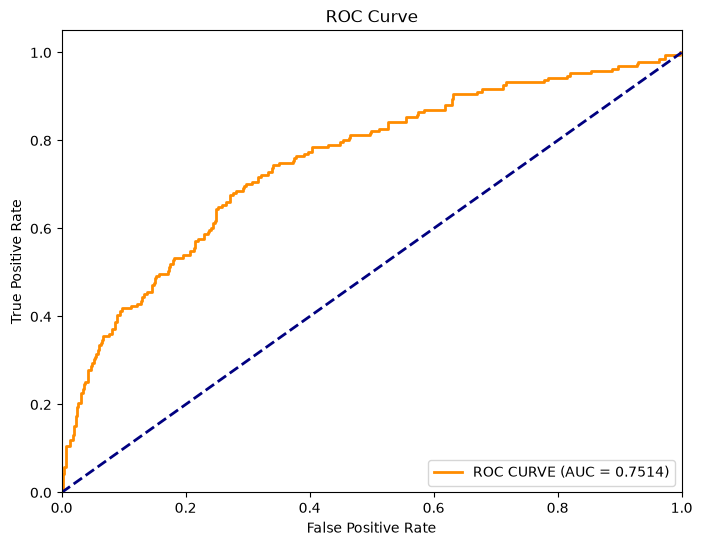

In [11]:
# 计算ROC曲线和AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)



# 绘制ROC曲线
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC CURVE (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()